# A Desert Turning Green: Leaf Area Index Change in East Owainat, Egypt (Landsat 8/9, 2014–2025)

East Owainat (Sharq El Owainat) is a land reclamation project in Egypt's Western Desert, close to the borders with
Libya and Sudan. Crops such as wheat and potatoes are grown in circular center-pivot fields, watered with fossil
groundwater from the Nubian Sandstone Aquifer. The farmed area has grown quickly in recent years, which makes it a
good place to watch **leaf area index (LAI)** change over time: bare sand on one date, a full crop canopy on another.

I use the same indices as my original Earth Engine script, from Landsat 8 and 9 surface reflectance:

| Index | Formula |
|---|---|
| **NDVI** | (NIR − Red) / (NIR + Red) |
| **EVI** | 2.5 × (NIR − Red) / (NIR + 6·Red − 7.5·Blue + 1) |
| **LAI** | 3.618 × EVI − 0.118 (empirical, developed for crops; Boegh et al. 2002) |

**What I do here**

1. Map the **peak LAI of every year** and how it changed between the first and last years.
2. Measure how much land was **green (LAI > 1) each year**, a simple way to track the expansion of the fields.
3. Let the data pick **three sample spots automatically**: the biggest gain, the biggest loss and a field that stayed
   green. I then draw their 8-day LAI and NDVI curves, as in my original charts (which used a point I drew by hand).

> Based on my original Earth Engine JavaScript script (8-day Landsat composites of NDVI, EVI and LAI).

## 1. Setup

Slow Earth Engine results are saved to `outputs/lai_owainat/` as they are computed, so **Restart & Run All** after a
restart is quick.

In [ ]:
import os, io, json
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
import requests
from PIL import Image
from scipy import stats

ee.Initialize(project="add your GEE username here")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 11})

C:\Users\moham\anaconda3\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.18) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


## 2. Study area and settings

In [2]:
# Folders where I save tables, map images and figures
FIG_DIR, OUT_DIR = "figures/lai_owainat", "outputs/lai_owainat"
MAP_DIR = f"{OUT_DIR}/map_images"
for d in (FIG_DIR, OUT_DIR, MAP_DIR):
    os.makedirs(d, exist_ok=True)

# A box around the East Owainat farming area (longitude/latitude). Any area with big LAI changes works:
# a new irrigation scheme, a burned forest, a deforestation front, a drained wetland...
BBOX = [28.20, 22.30, 29.20, 23.00]
aoi = ee.Geometry.Rectangle(BBOX)
PLACE = "East Owainat, Egypt"

START_YEAR, END_YEAR = 2014, 2025     # Landsat 8 from 2013 (first full year 2014), Landsat 9 from late 2021
COMPARE_YEARS = 3                     # the change map compares the first 3 years with the last 3
MAX_CLOUD = 30                        # scene-level cloud filter (%); clouds are also removed pixel by pixel
INTERVAL = 8                          # composite length in days, as in my original script
GREEN_LAI = 1.0                       # a pixel counts as "green" (crops growing) above this LAI
STATS_SCALE = 60                      # metres for the yearly area statistics (30 m is slower)

# Optional: your own sample points instead of the automatic ones, e.g. {"My field": (28.55, 22.65)}
MY_SITES = {}
FORCE_RECOMPUTE = False

## 3. Landsat preprocessing

Compared with my original script, I remove clouds and cloud shadows pixel by pixel with the `QA_PIXEL` band instead of
keeping only scenes with under 10% cloud. In a desert that rarely matters, but it makes the notebook safe to reuse
in cloudier places. LAI is kept between 0 and 8 to drop unrealistic values over bright sand.

In [3]:
def prepare(img):
    qa = img.select("QA_PIXEL")
    clear = qa.bitwiseAnd(0b11110).eq(0)       # bits 1-4: dilated cloud, cirrus, cloud, cloud shadow
    bands = img.select("SR_B.*").multiply(2.75e-05).add(-0.2).updateMask(clear)
    ndvi = bands.normalizedDifference(["SR_B5", "SR_B4"]).rename("ndvi")
    evi = bands.expression("2.5 * ((nir - red) / (nir + 6 * red - 7.5 * blue + 1))",
                           {"nir": bands.select("SR_B5"), "red": bands.select("SR_B4"), "blue": bands.select("SR_B2")}
                           ).rename("evi")
    lai = evi.multiply(3.618).subtract(0.118).clamp(0, 8).rename("lai")
    return ee.Image.cat(ndvi, evi, lai).copyProperties(img, ["system:time_start"])

landsat = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
             .merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_L2"))
             .filterDate(f"{START_YEAR}-01-01", f"{END_YEAR + 1}-01-01")
             .filterBounds(aoi)
             .filter(ee.Filter.lt("CLOUD_COVER", MAX_CLOUD)))
index = landsat.map(prepare)

def peak_lai(y0, y1):
    # "Peak" LAI = the 90th percentile over the period: close to the maximum, but not fooled by a single odd value
    return (index.filterDate(f"{y0}-01-01", f"{y1 + 1}-01-01").select("lai")
                 .reduce(ee.Reducer.percentile([90])).rename("lai"))

print(f"Landsat scenes: {landsat.size().getInfo()}")

Landsat scenes: 1432


## 4. How much land was green each year?

For each year I take the peak LAI of every pixel and add up the area where it was above `GREEN_LAI`. Each year is
saved as soon as it is done.

In [4]:
YEARS_CSV = f"{OUT_DIR}/green_area_by_year.csv"
px = ee.Image.pixelArea().divide(1e6)

saved = pd.read_csv(YEARS_CSV) if os.path.exists(YEARS_CSV) and not FORCE_RECOMPUTE else pd.DataFrame()
done_years = set(saved["year"]) if len(saved) else set()
for year in range(START_YEAR, END_YEAR + 1):
    if year in done_years:
        continue
    peak = peak_lai(year, year)
    vals = ee.Image.cat(
        peak.gt(GREEN_LAI).selfMask().multiply(px).rename("green_km2"),
        peak.gt(3).selfMask().multiply(px).rename("dense_km2"),        # full crop canopy
        peak.rename("mean_peak_lai"),
    ).reduceRegion(ee.Reducer.sum().combine(ee.Reducer.mean(), sharedInputs=True), aoi,
                   STATS_SCALE, maxPixels=1e13, tileScale=8).getInfo()
    row = {"year": year, "green_km2": vals.get("green_km2_sum"), "dense_km2": vals.get("dense_km2_sum"),
           "mean_peak_lai": vals.get("mean_peak_lai_mean"),
           "scenes": index.filterDate(f"{year}-01-01", f"{year + 1}-01-01").size().getInfo()}
    saved = pd.concat([saved, pd.DataFrame([row])], ignore_index=True)
    saved.to_csv(YEARS_CSV, index=False)
    print(f"{year}: green area {row['green_km2'] or 0:,.0f} km²")

green = saved.sort_values("year").set_index("year").astype(float)
first, last = green.iloc[0], green.iloc[-1]
slope, intercept, lo, hi = stats.theilslopes(green["green_km2"].values, green.index.values.astype(float))
summary = pd.Series({
    f"Green area {int(green.index[0])} (km²)": round(first["green_km2"], 1),
    f"Green area {int(green.index[-1])} (km²)": round(last["green_km2"], 1),
    "Change (km²)": round(last["green_km2"] - first["green_km2"], 1),
    "Change (×)": round(last["green_km2"] / first["green_km2"], 2) if first["green_km2"] else np.nan,
    "Trend (km²/year, Theil–Sen)": round(slope, 1),
    "Year with the largest green area": int(green["green_km2"].idxmax()),
}, name="value")
summary.to_csv(f"{OUT_DIR}/green_area_summary.csv")
display(green.round(2))
summary.to_frame()

2014: green area 394 km²
2015: green area 526 km²
2016: green area 506 km²
2017: green area 533 km²
2018: green area 563 km²
2019: green area 503 km²
2020: green area 511 km²
2021: green area 598 km²
2022: green area 566 km²
2023: green area 636 km²
2024: green area 697 km²
2025: green area 737 km²


,green_km2,dense_km2,mean_peak_lai,scenes
year,,,,
2014,394.34,0.27,0.28,89.0
2015,525.53,0.11,0.31,89.0
2016,506.41,2.27,0.32,89.0
2017,532.96,0.81,0.31,88.0
2018,562.68,0.56,0.32,89.0
2019,502.65,3.90,0.32,89.0
2020,511.36,2.21,0.32,90.0
2021,597.58,2.15,0.34,106.0
2022,566.45,2.11,0.33,173.0


,value
Green area 2014 (km²),394.30
Green area 2025 (km²),737.10
Change (km²),342.80
Change (×),1.87
"Trend (km²/year, Theil–Sen)",22.90
Year with the largest green area,2025.00


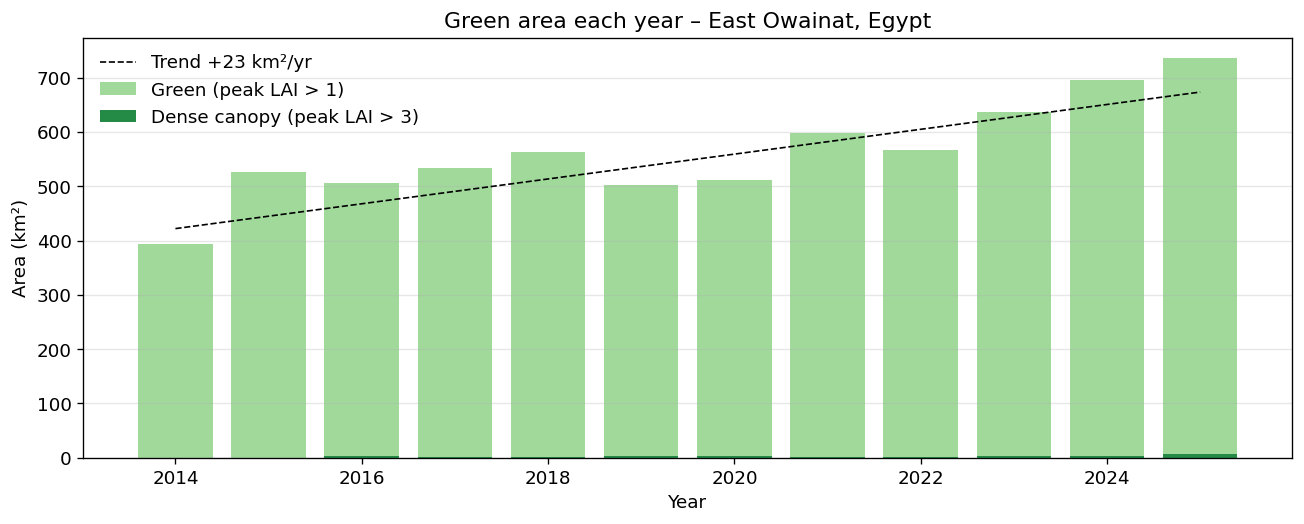

In [5]:
fig, ax1 = plt.subplots(figsize=(11, 4.5))
years = green.index.astype(int)
ax1.bar(years, green["green_km2"], color="#a1d99b", label=f"Green (peak LAI > {GREEN_LAI:g})")
ax1.bar(years, green["dense_km2"], color="#238b45", label="Dense canopy (peak LAI > 3)")
ax1.plot(years, intercept + slope * years, "k--", lw=1, label=f"Trend {slope:+.0f} km²/yr")
ax1.set(xlabel="Year", ylabel="Area (km²)", title=f"Green area each year – {PLACE}")
ax1.legend(frameon=False, loc="upper left"); ax1.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/01_green_area_by_year.png"); plt.show()

## 5. Maps: peak LAI over the years and the change

The maps are static images so they show on GitHub; each one is saved the first time it is made.

  lai_change at 900px failed: {
  "error": {
    "code": 400,
    "message": "User memory limit exceeded.",
    "status": "INVALID_ARGUMENT"
  }
} - trying smaller


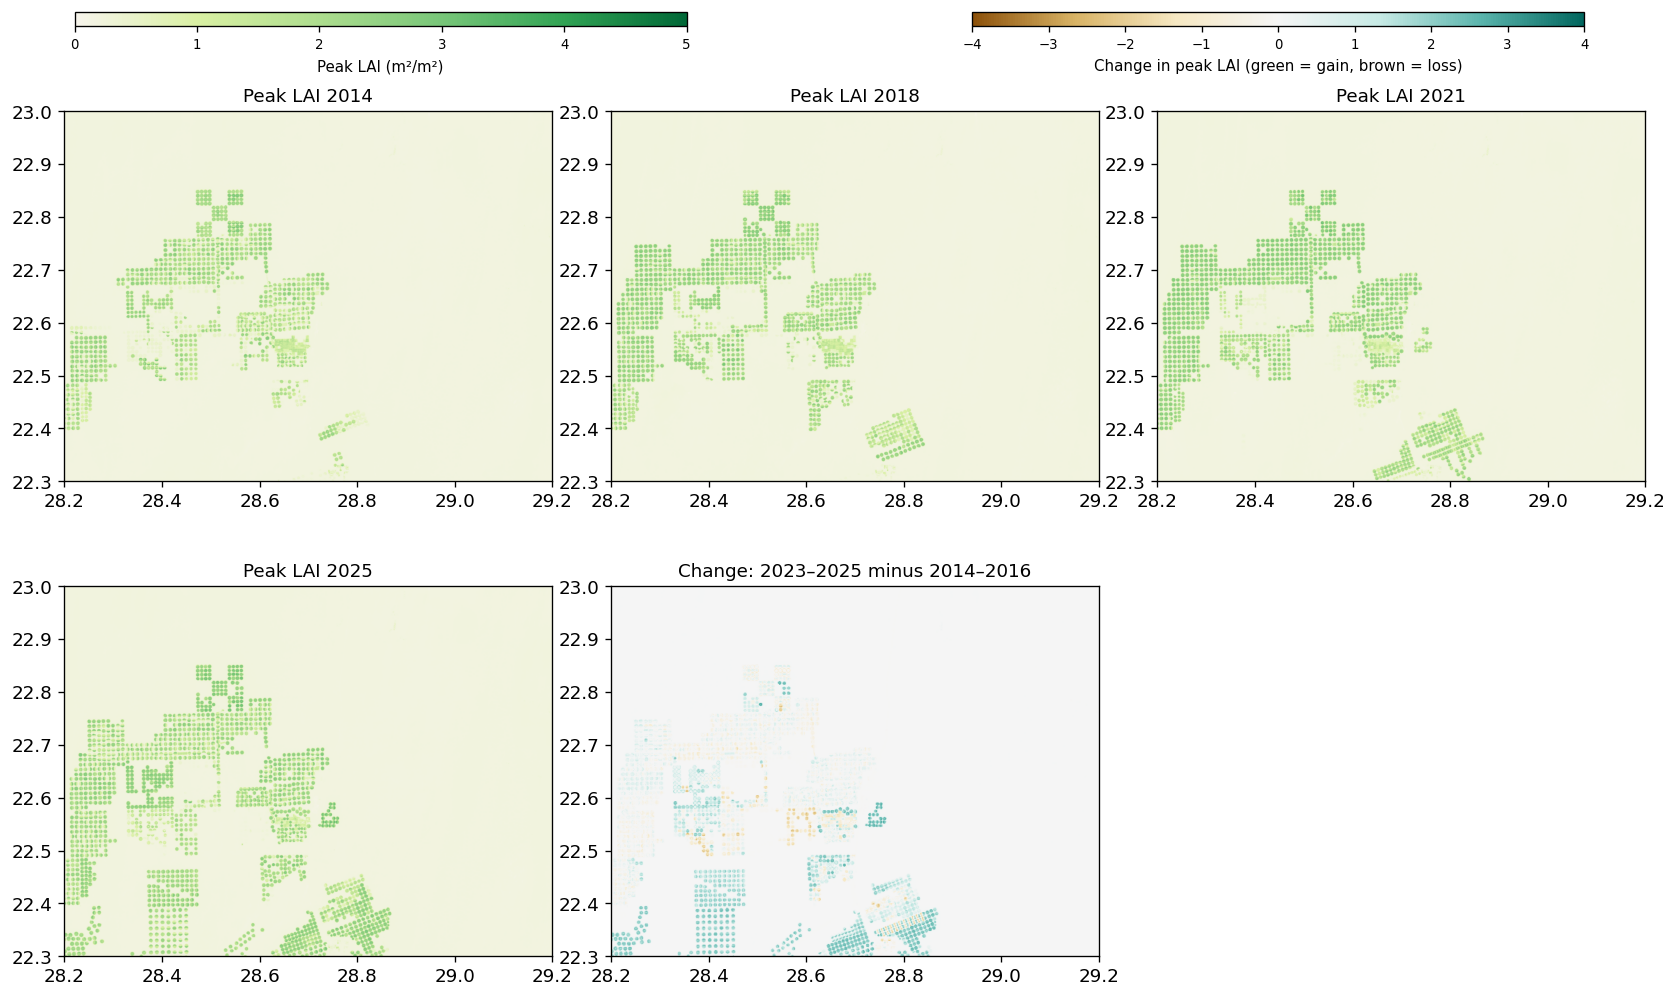

In [6]:
def thumb(key, vis_image, region, dims=900):
    path = f"{MAP_DIR}/{key}.png"
    if os.path.exists(path) and not FORCE_RECOMPUTE:
        return np.array(Image.open(path))
    for size in (dims, 700, 500):
        try:
            url = vis_image.getThumbURL({"region": region, "dimensions": size, "crs": "EPSG:4326", "format": "png"})
            resp = requests.get(url, timeout=600); resp.raise_for_status()
            img = Image.open(io.BytesIO(resp.content)); img.save(path)
            return np.array(img)
        except Exception as e:
            reason = getattr(getattr(e, "response", None), "text", "") or str(e)
            print(f"  {key} at {size}px failed: {reason[:120].strip()} - trying smaller")
    raise RuntimeError(f"Could not render {key}")

LAI_PAL = ["f7f4ec", "d9f0a3", "addd8e", "78c679", "31a354", "006837"]
DIFF_PAL = ["8c510a", "d8b365", "f6e8c3", "f5f5f5", "c7eae5", "5ab4ac", "01665e"]
extent = [BBOX[0], BBOX[2], BBOX[1], BBOX[3]]
aspect = 1 / np.cos(np.deg2rad(np.mean(BBOX[1::2])))

early = peak_lai(START_YEAR, START_YEAR + COMPARE_YEARS - 1)
late = peak_lai(END_YEAR - COMPARE_YEARS + 1, END_YEAR)
change = late.subtract(early).rename("change")

map_years = sorted(set(np.linspace(START_YEAR, END_YEAR, 4).round().astype(int)))
panels = [(thumb(f"peak_lai_{y}", peak_lai(y, y).visualize(min=0, max=5, palette=LAI_PAL), aoi), f"Peak LAI {y}")
          for y in map_years]
panels.append((thumb("lai_change", change.visualize(min=-4, max=4, palette=DIFF_PAL), aoi),
               f"Change: {END_YEAR - COMPARE_YEARS + 1}–{END_YEAR} minus {START_YEAR}–{START_YEAR + COMPARE_YEARS - 1}"))

fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
fig.subplots_adjust(top=0.86, hspace=0.25, wspace=0.12)
for ax, (arr, title) in zip(axes.flat, panels):
    ax.imshow(arr, extent=extent); ax.set_title(title, fontsize=11); ax.set_aspect(aspect)
for ax in list(axes.flat)[len(panels):]:
    ax.axis("off")

# Small colour bars above the figure, so they do not cover the maps
for (x0, pal, lo_v, hi_v, label) in [(0.13, LAI_PAL, 0, 5, "Peak LAI (m²/m²)"),
                                     (0.57, DIFF_PAL, -4, 4, "Change in peak LAI (green = gain, brown = loss)")]:
    cax = fig.add_axes([x0, 0.93, 0.30, 0.013])
    sm = plt.cm.ScalarMappable(cmap=LinearSegmentedColormap.from_list("p", ["#" + p for p in pal]), norm=Normalize(lo_v, hi_v))
    cb = fig.colorbar(sm, cax=cax, orientation="horizontal"); cb.set_label(label, fontsize=9); cb.ax.tick_params(labelsize=8)
fig.savefig(f"{FIG_DIR}/02_peak_lai_maps.png", bbox_inches="tight"); plt.show()

## 6. Sample spots and their LAI curves

In my original script I drew a point by hand (`geometry2`). Here I let the change map choose three spots: the
**largest gain**, the **largest loss**, and a spot that was **green in both periods**. For each one I extract every clear
Landsat observation (a very light request) and build 8-day maximum composites, exactly as in my original script.

In [8]:
SITES_JSON = f"{OUT_DIR}/sample_sites.json"
if MY_SITES:
    sites = MY_SITES
elif os.path.exists(SITES_JSON) and not FORCE_RECOMPUTE:
    sites = {k: tuple(v) for k, v in json.load(open(SITES_JSON)).items()}
else:
    pts = (ee.Image.cat(early.rename("early"), late.rename("late"), change, ee.Image.pixelLonLat())
             .sample(region=aoi, scale=90, numPixels=3000, seed=1, geometries=False, tileScale=16)
             .getInfo()["features"])
    s = pd.DataFrame([p["properties"] for p in pts]).dropna()
    gain = s.loc[s["change"].idxmax()]
    loss = s.loc[s[s["early"] > 2]["change"].idxmin()] if (s["early"] > 2).any() else s.loc[s["change"].idxmin()]
    steady_pool = s[(s["early"] > 2.5) & (s["late"] > 2.5)]
    steady = steady_pool.loc[(steady_pool["change"].abs()).idxmin()] if len(steady_pool) else None
    sites = {"Largest gain": (gain["longitude"], gain["latitude"]),
             "Largest loss": (loss["longitude"], loss["latitude"])}
    if steady is not None:
        sites["Green in both periods"] = (steady["longitude"], steady["latitude"])
    json.dump(sites, open(SITES_JSON, "w"), indent=1)
for name, (x, y) in sites.items():
    print(f"{name}: {x:.4f}, {y:.4f}")

SITES_CSV = f"{OUT_DIR}/sample_sites_8day.csv"
if os.path.exists(SITES_CSV) and not FORCE_RECOMPUTE and not MY_SITES:
    series = pd.read_csv(SITES_CSV, parse_dates=["date"])
else:
    frames = []
    for name, (x, y) in sites.items():
        pt = ee.Geometry.Point([x, y])
        region = index.filterBounds(pt).getRegion(pt, 30).getInfo()
        obs = pd.DataFrame(region[1:], columns=region[0]).dropna(subset=["lai"]).assign(site=name)
        obs["obs_date"] = pd.to_datetime(obs["time"], unit="ms")
        frames.append(obs)
        print(f"{name}: {len(obs)} clear observations")
    raw = pd.concat(frames, ignore_index=True)
    origin = pd.Timestamp(f"{START_YEAR}-01-01")
    raw["date"] = origin + pd.to_timedelta((raw["obs_date"] - origin).dt.days // INTERVAL * INTERVAL, unit="D")
    series = raw.groupby(["site", "date"])[["ndvi", "evi", "lai"]].max().reset_index().sort_values("date")
    series.round(4).to_csv(SITES_CSV, index=False)

per_site = series.assign(year=series["date"].dt.year).groupby(["site", "year"])["lai"].max().unstack("site")
per_site.round(2).to_csv(f"{OUT_DIR}/sample_sites_peak_lai_by_year.csv")
per_site.round(2)

Largest gain: 28.7469, 22.3388
Largest loss: 28.6029, 22.5595
Green in both periods: 28.2254, 22.4625
Largest gain: 698 clear observations
Largest loss: 358 clear observations
Green in both periods: 697 clear observations


site,Green in both periods,Largest gain,Largest loss
year,,,
2014,2.40,0.23,3.04
2015,2.80,0.21,2.59
2016,2.95,0.24,2.15
2017,2.63,0.20,0.58
2018,2.83,0.18,0.58
2019,1.68,0.21,0.52
2020,2.76,0.21,0.51
2021,2.77,0.18,0.50
2022,2.88,0.21,0.55


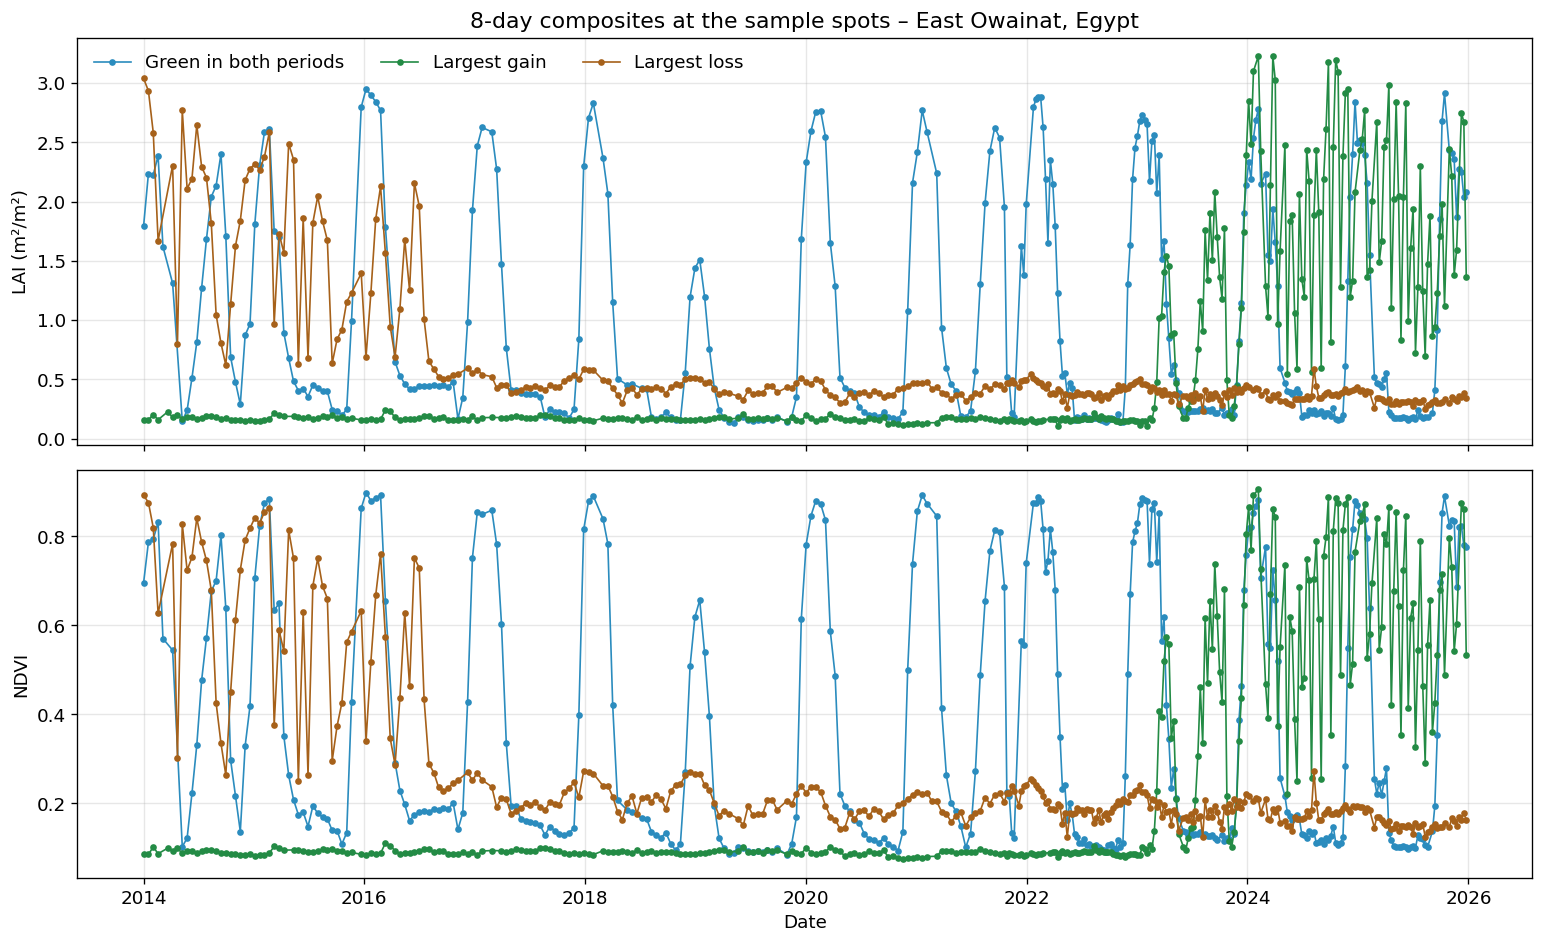

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
colors = {"Largest gain": "#238b45", "Largest loss": "#a6611a", "Green in both periods": "#2b8cbe"}
for ax, col, label in zip(axes, ["lai", "ndvi"], ["LAI (m²/m²)", "NDVI"]):
    for name, g in series.groupby("site"):
        ax.plot(g["date"], g[col], "o-", ms=3, lw=1, color=colors.get(name), label=name)
    ax.set_ylabel(label); ax.grid(alpha=0.3)
axes[0].legend(frameon=False, ncol=3, loc="upper left")
axes[0].set_title(f"8-day composites at the sample spots – {PLACE}")
axes[1].set_xlabel("Date")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/03_sample_spots_lai_ndvi.png"); plt.show()

## 7. Notes

- **Data:** USGS Landsat 8/9 Collection 2 Level-2 surface reflectance (scale 2.75e-05, offset −0.2).
- **LAI** uses the empirical EVI relation of Boegh et al. (2002), developed for crops, which suits irrigated fields;
  in forests or sparse shrubland it is only approximate.
- In this region the main crops are grown in the cool season (roughly November to April), unlike the May–October window in
  my original charts, so I show the whole year.
- A field can look "lost" in one year simply because it was left fallow or rotated; the green area and the change map are
  best read together with the year-by-year values of the sample spots.
- **Another place:** change `BBOX` and `PLACE`, and set `FORCE_RECOMPUTE = True` once (or use new folder names) so old
  results are not reused. The automatic sample spots adapt to the new area.